# Profit Diagnostic · 01 · Data audit and exploration
**Dataset:** Microsoft AdventureWorksDW2022, reseller channel (`FactResellerSales`) — public sample data for a fictional bicycle company.
**Goal of this notebook:** prove the data can carry the analysis before any finding is written. Every check records a result and a decision in a data-quality log.

**How to run**
1. Restore `AdventureWorksDW2022.bak` in SQL Server and run `06_SQL/00_setup_views.sql`.
2. `pip install pandas matplotlib pyodbc`, then run all cells. Set `PD_SERVER` if your instance is not `localhost`.
3. No SQL Server? Unzip Microsoft's *AdventureWorksDW-data-warehouse-install-script.zip* into `03_Raw_Data/` and set `PD_SOURCE=csv`.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pd_data as pdd          # loading + core calculations (same logic as the SQL scripts)
import pd_charts as ch         # chart style

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 30)
FIG = Path("../14_Final_Report/figures"); FIG.mkdir(parents=True, exist_ok=True)

# Where the data comes from:
#   "sqlserver" -> dbo.vw_pd_sales_line in AdventureWorksDW2022 (run 06_SQL/00_setup_views.sql first)
#   "csv"       -> Microsoft's CSV install package, unzipped into 03_Raw_Data/
SOURCE = os.getenv("PD_SOURCE", "sqlserver")
SERVER = os.getenv("PD_SERVER", "localhost")      # e.g. "localhost\\SQLEXPRESS"
df = pdd.load_sales_lines(source=SOURCE, server=SERVER)
p1 = df[df["period"] == "P1"]
print(f"Loaded {len(df):,} order lines from {SOURCE}; net sales {df.net_sales.sum():,.2f}")

Loaded 60,855 order lines from csv; net sales 80,450,596.98


In [2]:
log = []   # data-quality log: one row per check
def record(check, result, decision):
    log.append({"check": check, "result": result, "decision": decision})
    print(f"✔ {check}: {result}")

## 1. Grain, volume and completeness

In [3]:
n_lines = len(df)
n_unique = len(df[["order_number", "order_line"]].drop_duplicates())
record("One row per order line", f"{n_lines:,} rows = {n_unique:,} distinct order lines", "Grain confirmed")
record("Orders, SKUs, resellers, reps",
       f"{df.order_number.nunique():,} orders | {df.sku.nunique()} SKUs ({df.product_key.nunique()} product keys) | "
       f"{df.reseller_key.nunique()} resellers | {df.employee_key.nunique()} reps",
       "SKU, not ProductKey, is the product ID (ProductKey is Type 2)")
nulls = df[["qty", "unit_price", "net_sales", "cogs", "discount_pct", "order_date"]].isna().sum()
record("Missing values in analysis columns", f"{int(nulls.sum())} nulls", "No imputation needed")

✔ One row per order line: 60,855 rows = 60,855 distinct order lines
✔ Orders, SKUs, resellers, reps: 3,796 orders | 250 SKUs (334 product keys) | 635 resellers | 17 reps
✔ Missing values in analysis columns: 0 nulls


## 2. Do the money columns add up?
Unit price or line total? This is the check that failed on my previous retail dataset, so it comes first.

In [4]:
checks = {
    "UnitPrice × Qty = ExtendedAmount": (df.unit_price * df.qty - df.invoice_gross).abs() > 0.01,
    "Extended × Discount% = DiscountAmount": (df.invoice_gross * df.discount_pct - df.line_discount).abs() > 0.01,
    "Extended − Discount = SalesAmount": (df.invoice_gross - df.line_discount - df.net_sales).abs() > 0.01,
    "StandardCost × Qty = TotalProductCost": (df.unit_cost * df.qty - df.cogs).abs() > 0.01,
}
for name, bad in checks.items():
    record(name, f"{int(bad.sum())} mismatches", "Unit prices confirmed" if bad.sum() == 0 else "INVESTIGATE")
record("Impossible values", f"{int((df.qty <= 0).sum())} non-positive qty | {int((df.net_sales < 0).sum())} negative sales",
       "None to remove")
below = (df.net_sales < df.cogs).sum()
record("Lines sold below standard cost", f"{below:,} of {len(df):,} ({below/len(df):.0%})",
       "Not an error: main business question for Q1/Q3")

✔ UnitPrice × Qty = ExtendedAmount: 0 mismatches
✔ Extended × Discount% = DiscountAmount: 0 mismatches
✔ Extended − Discount = SalesAmount: 0 mismatches
✔ StandardCost × Qty = TotalProductCost: 0 mismatches
✔ Impossible values: 0 non-positive qty | 0 negative sales
✔ Lines sold below standard cost: 21,829 of 60,855 (36%)


## 3. Which months can be compared?

In [5]:
monthly = df.assign(month=df.order_date.dt.to_period("M")).groupby("month").agg(
    net_sales=("net_sales", "sum"), gross_profit=("gross_profit", "sum"))
monthly["gross_margin_pct"] = monthly.gross_profit / monthly.net_sales * 100
all_months = pd.period_range(monthly.index.min(), monthly.index.max(), freq="M")
missing = [str(m) for m in all_months.difference(monthly.index)]
record("Month coverage", f"{monthly.index.min()} to {monthly.index.max()}; missing: {', '.join(missing)}",
       "Compare Dec 2011–Nov 2012 (P0) with Dec 2012–Nov 2013 (P1)")
monthly.tail(14)

✔ Month coverage: 2010-12 to 2013-11; missing: 2011-02, 2011-04, 2011-06


,net_sales,gross_profit,gross_margin_pct
month,,,
2012-10,"2,880,752.68","115,206.59",4.00
2012-11,"1,987,872.71","100,408.55",5.05
2012-12,"2,665,650.54","-181,857.11",-6.82
2013-01,"4,212,971.51","-250,821.21",-5.95
2013-02,"4,047,574.04","-277,925.03",-6.87
2013-03,"2,282,115.88","-3,230.94",-0.14
2013-04,"3,483,161.40","22,406.70",0.64
2013-05,"3,510,948.73","30,988.99",0.88
2013-06,"1,662,547.32","4,585.38",0.28


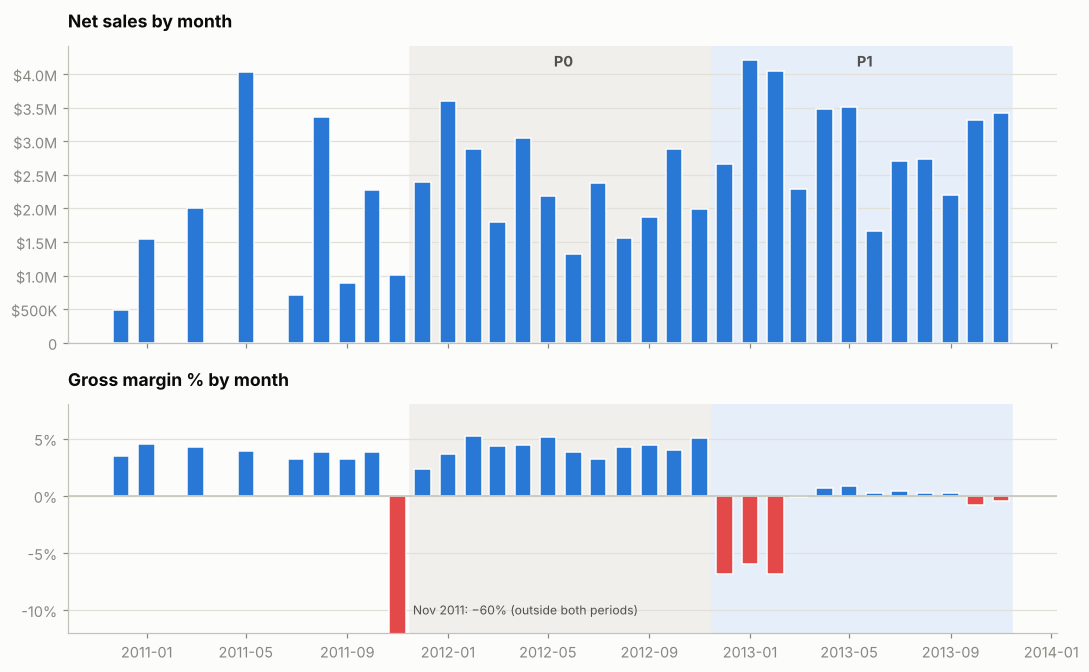

In [6]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
x = monthly.index.to_timestamp()
a1.bar(x, monthly.net_sales, width=20, color=ch.GAIN, edgecolor=ch.SURFACE)
a1.set_title("Net sales by month"); ch._money_axis(a1)
a2.bar(x, monthly.gross_margin_pct, width=20,
       color=[ch.GAIN if v >= 0 else ch.LOSS for v in monthly.gross_margin_pct], edgecolor=ch.SURFACE)
a2.axhline(0, color=ch.AXIS, lw=1); a2.set_title("Gross margin % by month")
a2.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%"); a2.set_ylim(-12, 8)
a2.annotate("Nov 2011: −60% (outside both periods)", (x[list(monthly.index.astype(str)).index("2011-11")], -12),
            xytext=(10, 12), textcoords="offset points", fontsize=8, color=ch.INK_2)
for a in (a1, a2):
    a.axvspan(pd.Timestamp("2011-11-16"), pd.Timestamp("2012-11-15"), color="#f0efec", zorder=0)
    a.axvspan(pd.Timestamp("2012-11-16"), pd.Timestamp("2013-11-15"), color="#e6eef9", zorder=0)
a1.text(pd.Timestamp("2012-05-20"), a1.get_ylim()[1]*0.93, "P0", ha="center", color=ch.INK_2, fontweight="bold")
a1.text(pd.Timestamp("2013-05-20"), a1.get_ylim()[1]*0.93, "P1", ha="center", color=ch.INK_2, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "fig01_monthly_trend.png"); plt.show()

**Reading.** Margin sat around 3–5% until November 2012, then turned negative from December 2012 — the month the new Touring range and price-list changes start appearing. November 2011 is an isolated −60% month outside both periods; it is logged, not used.

## 4. The two periods: is the client's brief true?

In [7]:
periods = pdd.summarise(df[df.period.notna()], "period")
chg = periods.loc["P1"] - periods.loc["P0"]
record("Brief: sales grew but profit didn't",
       f"net sales {chg.net_sales/periods.loc['P0','net_sales']:+.1%}; gross profit "
       f"{periods.loc['P0','gross_profit']:,.0f} → {periods.loc['P1','gross_profit']:,.0f}",
       "Brief confirmed by data")
periods

✔ Brief: sales grew but profit didn't: net sales +29.8%; gross profit 1,153,445 → -673,727


,lines,units,net_sales,cogs,gross_profit,gross_margin_pct
period,,,,,,
P0,21670,78959,"27,921,670.52","26,768,225.75","1,153,444.77",4.13
P1,30726,113529,"36,240,484.70","36,914,211.81","-673,727.11",-1.86


## 5. How is the invoice price built?

In [8]:
price_build = (df.assign(to_list=(df.unit_price / df.list_price).round(3),
                          to_dealer=(df.unit_price / df.dealer_price).round(3))
               .groupby(["discount_pct", "to_list", "to_dealer"]).size().rename("lines").reset_index())
record("Unit price vs dealer price",
       "undiscounted lines invoice at dealer price (60% of list); promoted lines invoice BELOW dealer price "
       "and then get the line discount on top",
       "Promotion reduces price twice: raise with client; model as waterfall step")
price_build

✔ Unit price vs dealer price: undiscounted lines invoice at dealer price (60% of list); promoted lines invoice BELOW dealer price and then get the line discount on top


,discount_pct,to_list,to_dealer,lines
0,0.00,0.60,1.00,57573
1,0.02,0.58,0.97,1310
2,0.05,0.55,0.92,606
3,0.10,0.50,0.83,178
4,0.15,0.45,0.75,590
5,0.20,0.40,0.67,231
6,0.30,0.30,0.50,61
7,0.35,0.25,0.42,137
8,0.40,0.20,0.33,169


## 6. Data-quality log

In [9]:
quality_log = pd.DataFrame(log)
quality_log.index = quality_log.index + 1
quality_log.to_csv("../05_Data_Cleaning/data_quality_log.csv", index_label="id")
quality_log

,check,result,decision
1,One row per order line,"60,855 rows = 60,855 distinct order lines",Grain confirmed
2,"Orders, SKUs, resellers, reps","3,796 orders | 250 SKUs (334 product keys) | 6...","SKU, not ProductKey, is the product ID (Produc..."
3,Missing values in analysis columns,0 nulls,No imputation needed
4,UnitPrice × Qty = ExtendedAmount,0 mismatches,Unit prices confirmed
5,Extended × Discount% = DiscountAmount,0 mismatches,Unit prices confirmed
6,Extended − Discount = SalesAmount,0 mismatches,Unit prices confirmed
7,StandardCost × Qty = TotalProductCost,0 mismatches,Unit prices confirmed
8,Impossible values,0 non-positive qty | 0 negative sales,None to remove
9,Lines sold below standard cost,"21,829 of 60,855 (36%)",Not an error: main business question for Q1/Q3
10,Month coverage,"2010-12 to 2013-11; missing: 2011-02, 2011-04,...",Compare Dec 2011–Nov 2012 (P0) with Dec 2012–N...


**Conclusion.** The reseller data is clean (no nulls, no orphan keys, arithmetic reconciles to the cent), amounts are in USD, and the brief is confirmed. Two modelling decisions carry forward: **SKU** is the product key, and the comparison is **P0 (Dec 2011–Nov 2012) vs P1 (Dec 2012–Nov 2013)**.